# Function Transformer | Log Transform

In [36]:
import pandas as pd
import numpy as np

import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [37]:
df= pd.read_csv("titanic.csv",usecols=['Age','Fare','Survived'])

In [38]:
df['Age'].fillna(df['Age'].mean(),inplace=True)

C:\Users\Alok Kumar\AppData\Local\Temp\ipykernel_27952\694922604.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(),inplace=True)


In [39]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [40]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [41]:
x=df.iloc[:,1:3]
y=df.iloc[:,0]

In [ ]:
# train test split 

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

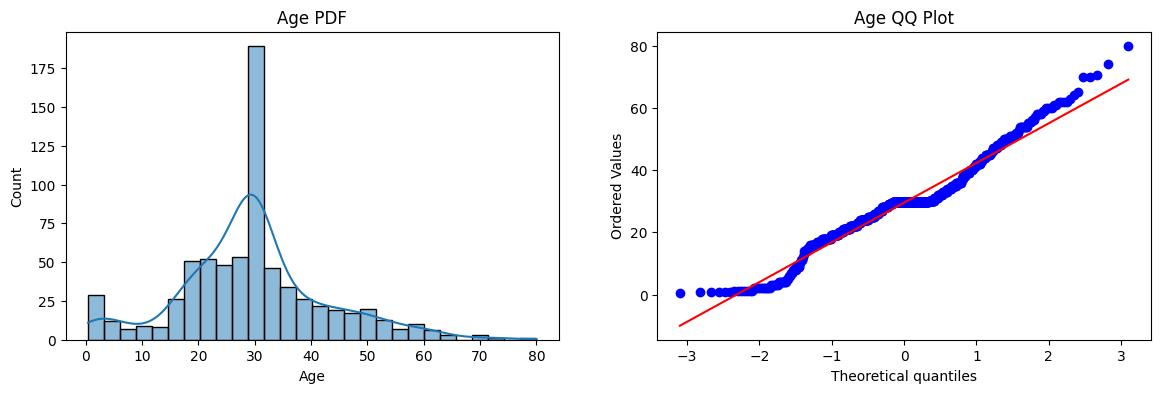

In [43]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# from scipy import stats

plt.figure(figsize=(14,4))

# PDF / Distribution Plot
plt.subplot(121)
sns.histplot(x_train["Age"], kde=True)
plt.title("Age PDF")

# QQ Plot
plt.subplot(122)
stats.probplot(x_train["Age"], dist="norm", plot=plt)
plt.title("Age QQ Plot")

plt.show()


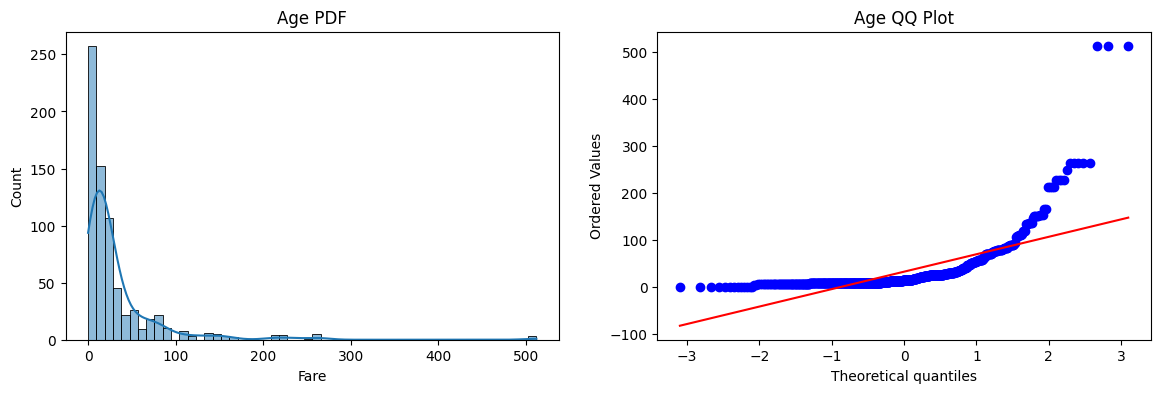

In [44]:
plt.figure(figsize=(14,4))

# PDF / Distribution Plot
plt.subplot(121)
sns.histplot(x_train["Fare"], kde=True)
plt.title("Age PDF")

# QQ Plot
plt.subplot(122)
stats.probplot(x_train["Fare"], dist="norm", plot=plt)
plt.title("Age QQ Plot")

plt.show()

In [ ]:
# Creating Logistic Regression model (Linear classification algorithm)
clf=LogisticRegression()

# Creating Decision Tree model (Tree-based classification algorithm)
clf2=DecisionTreeClassifier()

In [ ]:
# Train Logistic Regression model using training data
# It learns the relationship between input features and target labels
clf.fit(x_train,y_train)

# Train Decision Tree model using training data
# It creates decision rules by splitting the data
clf2.fit(x_train,y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [ ]:
# Predict test data using trained Logistic Regression model
# It returns predicted class label
y_pred=clf.predict(x_test)

# Predict test data using trained Decision Tree model
y_pred1=clf2.predict(x_test)

In [ ]:
print("accuracy score LR :",accuracy_score(y_test,y_pred))
print("accuracy score DT :",accuracy_score(y_test,y_pred1))


# Calculate accuracy of Logistic Regression predictions
# Compare actual values (y_test) with predicted values (y_pred)

accuracy score LR : 0.6480446927374302
accuracy score DT : 0.664804469273743


# LOG TRANSFORM

In [49]:
# use log transform
trf=FunctionTransformer (func=np.log1p)

In [ ]:
# Apply transformation (scaling/encoding/function transformation) on training data
# fit_transform() learns parameters from x_train and transforms the data

x_train_transformed=trf.fit_transform(x_train)

# Apply same transformation on test data
# transform() uses parameters learned from training data

x_test_transformed=trf.transform(x_test)

In [51]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

In [52]:
clf.fit(x_train_transformed,y_train)
clf2.fit(x_train_transformed,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [53]:
y_pred=clf.predict(x_test_transformed)
y_pred1=clf2.predict(x_test_transformed)

In [54]:
print("accuracy score LR :",accuracy_score(y_test,y_pred))
print("accuracy score DT :",accuracy_score(y_test,y_pred1))

accuracy score LR : 0.6815642458100558
accuracy score DT : 0.6759776536312849


In [55]:
x_transformed=trf.fit_transform(x)

clf=LogisticRegression()
clf2=DecisionTreeClassifier()

In [56]:
print("LR",np.mean(cross_val_score(clf,x_transformed,y,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,x_transformed,y,scoring='accuracy',cv=10)))


LR 0.678027465667915
DT 0.6577028714107367


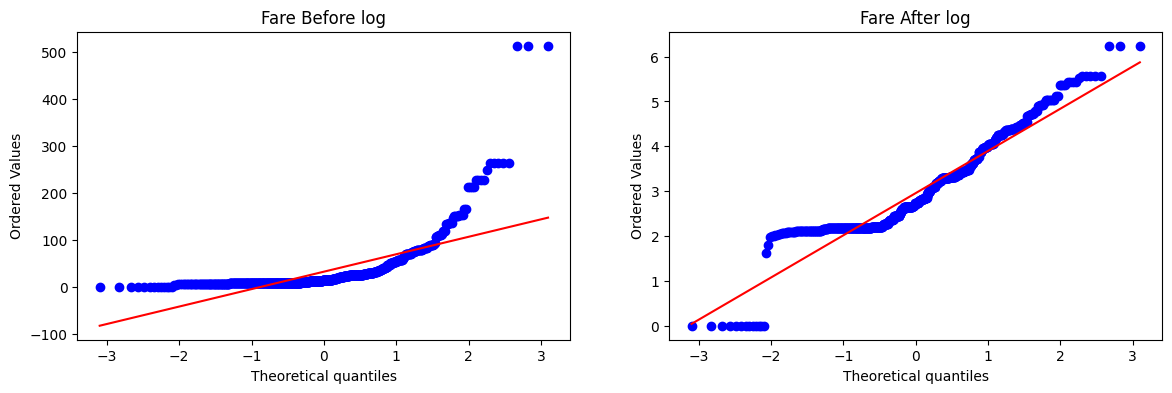

In [57]:
plt.figure(figsize=(14,4))


plt.subplot(121)
stats.probplot(x_train['Fare'],dist='norm',plot=plt)
plt.title('Fare Before log')


plt.subplot(122)
stats.probplot(x_train_transformed['Fare'],dist='norm',plot=plt)
plt.title('Fare After log')

plt.show()


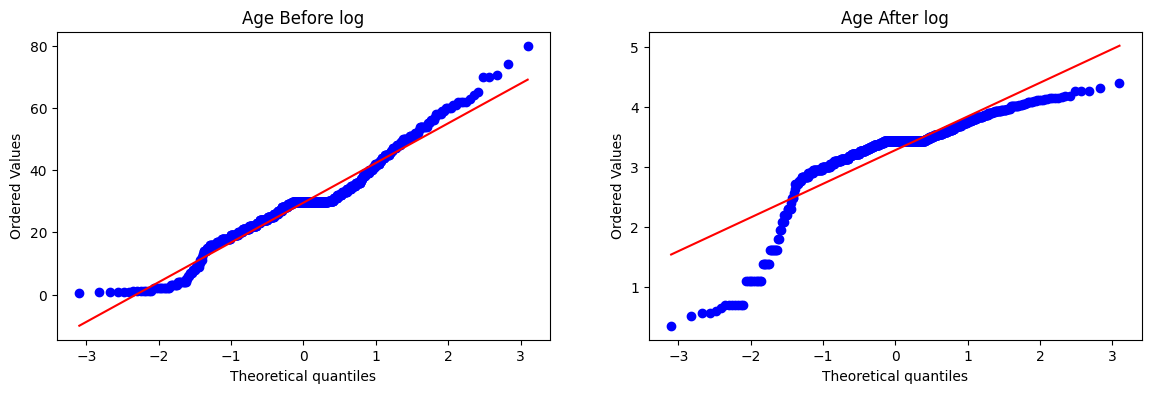

In [ ]:
plt.figure(figsize=(14,4))


plt.subplot(121)
stats.probplot(x_train['Age'],dist='norm',plot=plt)
plt.title('Age Before log')


plt.subplot(122)
stats.probplot(x_train_transformed['Age'],dist='norm',plot=plt)
plt.title('Age After log')

plt.show()

In [59]:
trf2=ColumnTransformer([('log',FunctionTransformer(np.log1p),['Fare'])],remainder='passthrough')
x_train_transformed2=trf2.fit_transform(x_train)
x_test_transformed2=trf2.fit_transform(x_test)

In [60]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

In [61]:
clf.fit(x_train_transformed2,y_train)
clf2.fit(x_train_transformed2,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [62]:
y_pred=clf.predict(x_test_transformed2)
y_pred2=clf2.predict(x_test_transformed2)

In [63]:
print("accuracy LR :",accuracy_score(y_test,y_pred))
print("accuracy DT :",accuracy_score(y_test,y_pred2))

accuracy LR : 0.6703910614525139
accuracy DT : 0.659217877094972


In [64]:
print(y_test.shape)
print(y_pred.shape)
print(y_pred2.shape)

(179,)
(179,)
(179,)


In [66]:
x_transformed2 = trf2.fit_transform(x)
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

In [69]:
print("LR",np.mean(cross_val_score(clf,x_transformed2,y,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,x_transformed2,y,scoring='accuracy',cv=10)))

LR 0.6712609238451936
DT 0.6655680399500625


In [94]:
def apply_transform(transform):
    x=df.iloc[:,1:3]
    y=df.iloc[:,0]
    trf2=ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder='passthrough')
    
    x_trans = trf.fit_transform(x)
    clf = LogisticRegression()

    print("accuracy", np.mean(cross_val_score(clf,x_trans,y,scoring='accuracy',cv=10)))

    plt.figure(figsize=(14,4))


    plt.subplot(121)
    stats.probplot(x['Fare'].to_numpy(),dist='norm',plot=plt)
    plt.title('Fare Before transform')


    plt.subplot(122)
    stats.probplot(x_trans.iloc[:,0].to_numpy(), dist='norm', plot=plt)
    plt.title('Fare After transform')

    plt.show()


    

accuracy 0.678027465667915


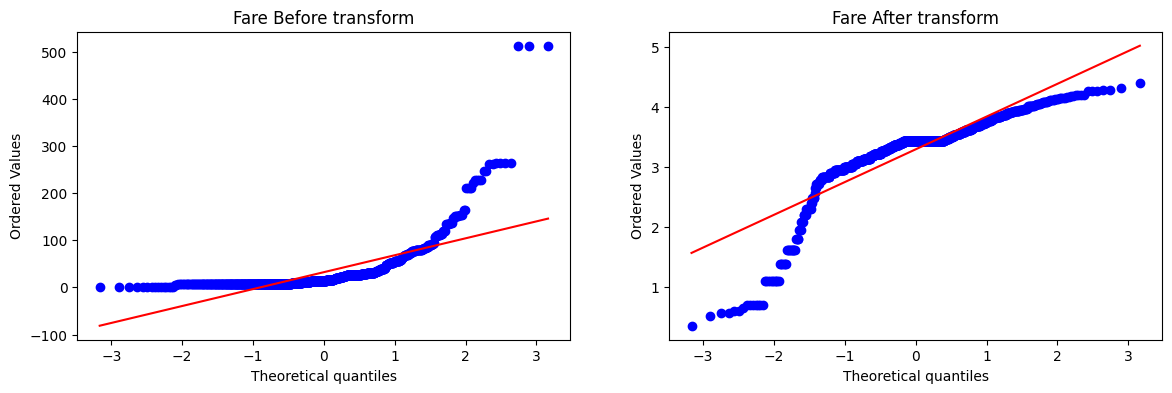

In [ ]:
apply_transform(lambda x:1/x)  # use  x**2, x**3,
